# **12.  Clasificador de margen máximo.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

## 12.3 Construcción de un conjunto de datos.

In [2]:
X = np.array([
    [1.0, 1.0],
    [1.5, 1.8],
    [2.0, 1.3],
    [2.2, 2.0],
    [2.8, 2.4],
    
    [4.5, 4.8],
    [5.0, 4.2],
    [5.3, 5.1],
    [5.8, 4.7],
    [6.2, 5.5]
])

y = np.array([-1, -1, -1, -1, -1,
               1,  1,  1,  1,  1])

In [3]:
datos = pd.DataFrame(X, columns=["X1", "X2"])

datos["Clases"] = y

datos

,X1,X2,Clases
0,1.0,1.0,-1
1,1.5,1.8,-1
2,2.0,1.3,-1
3,2.2,2.0,-1
4,2.8,2.4,-1
5,4.5,4.8,1
6,5.0,4.2,1
7,5.3,5.1,1
8,5.8,4.7,1
9,6.2,5.5,1


## 12.4 Visualización de los datos.

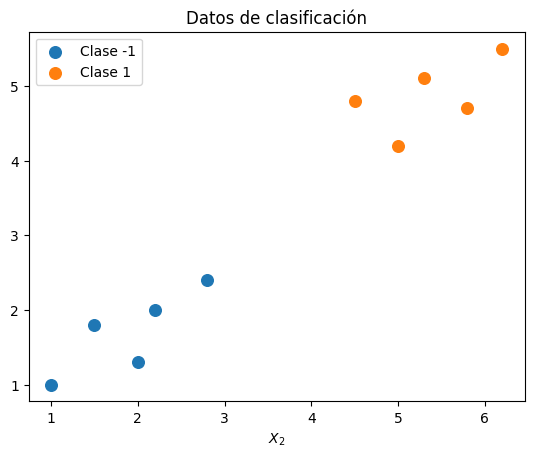

In [6]:
plt.Figure(figsize=(7,6))

for clase in np.unique(y):
    plt.scatter(
        X[y==clase, 0], X[y==clase, 1], label = f"Clase {clase}", s=70
    )

plt.xlabel("$X_1$")
plt.xlabel("$X_2$")
plt.title("Datos de clasificación")
plt.legend()
plt.show()

## 12.5 No toda frontera que clasifica perfectamente es igual.

In [12]:
puntos = np.linspace(0, 6, 100)

recta1 = 7 - puntos
recta2 = 11/2 - puntos
recta3 = 6 - puntos

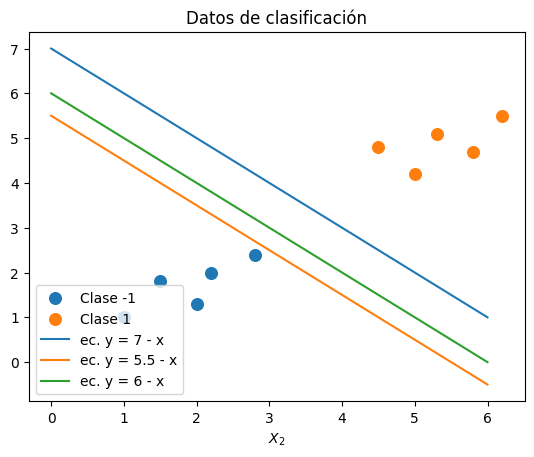

In [14]:
plt.Figure(figsize=(7,6))

for clase in np.unique(y):
    plt.scatter(
        X[y==clase, 0], X[y==clase, 1], label = f"Clase {clase}", s=70
    )

plt.plot(puntos, recta1, label = "ec. y = 7 - x")
plt.plot(puntos, recta2, label = "ec. y = 5.5 - x")
plt.plot(puntos, recta3, label = "ec. y = 6 - x")
plt.xlabel("$X_1$")
plt.xlabel("$X_2$")
plt.title("Datos de clasificación")
plt.legend()
plt.show()

## 12.6.1 ¿Cómo lo implementamos en Python?

In [15]:
modelo = SVC(kernel = "linear", C = 1e6)

modelo.fit(X,y)


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [16]:
y_pred = modelo.predict(X)
y_pred

array([-1, -1, -1, -1, -1,  1,  1,  1,  1,  1])

In [18]:
accuracy_score(y, y_pred)

1.0

## 12.7 La función de decisión.

In [19]:
modelo.coef_

array([[0.54086945, 0.45021752]])

In [20]:
modelo.intercept_

array([-3.59505786])

## 12.8 ¿Qué significa el valor de la función de decisión?

In [21]:
decision = modelo.decision_function(X)

decision

array([-2.60397089, -1.97336214, -1.92803617, -1.50471002, -1.00010133,
        0.9998988 ,  1.00020301,  1.56765962,  1.65800733,  2.23452914])

In [23]:
y_pred

array([-1, -1, -1, -1, -1,  1,  1,  1,  1,  1])

## 12.9 Frontera de decisión, margen y vectores de soporte.

In [24]:
def graficar_svm_lineal(modelo, X, y, titulo="Clasificador lineal"):
    
    plt.figure(figsize=(8, 6))
    
    for clase in np.unique(y):
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=70
        )
    
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    xx = np.linspace(x_min, x_max, 300)
    yy = np.linspace(y_min, y_max, 300)
    
    YY, XX = np.meshgrid(yy, xx)
    
    grid = np.c_[XX.ravel(), YY.ravel()]
    Z = modelo.decision_function(grid)
    Z = Z.reshape(XX.shape)
    
    plt.contour(
        XX,
        YY,
        Z,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"]
    )
    
    plt.scatter(
        modelo.support_vectors_[:, 0],
        modelo.support_vectors_[:, 1],
        s=180,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="Vectores de soporte"
    )
    
    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

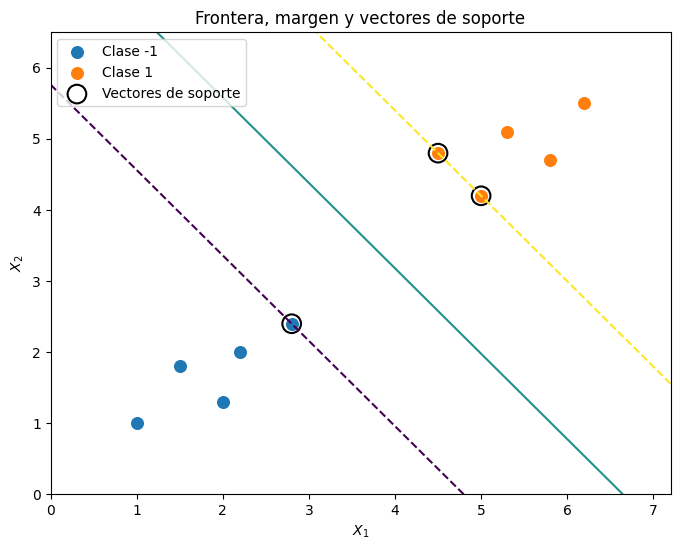

In [25]:
graficar_svm_lineal(modelo, X, y, titulo = "Frontera, margen y vectores de soporte")

## 12.10 Los vectores de soporte.

In [26]:
modelo.support_vectors_

array([[2.8, 2.4],
       [4.5, 4.8],
       [5. , 4.2]])

In [27]:
modelo.support_

array([4, 5, 6], dtype=int32)

In [28]:
modelo.n_support_

array([1, 2], dtype=int32)

## 12.11 ¿Todas las observaciones tienen la misma importancia?

In [29]:
X_modificado = X.copy()

In [30]:
X_modificado

array([[1. , 1. ],
       [1.5, 1.8],
       [2. , 1.3],
       [2.2, 2. ],
       [2.8, 2.4],
       [4.5, 4.8],
       [5. , 4.2],
       [5.3, 5.1],
       [5.8, 4.7],
       [6.2, 5.5]])

In [31]:
X_modificado[0] = [0.5, 0.5]

In [32]:
modelo_modificado = SVC(kernel = "linear", C=1e6)

modelo_modificado.fit(X_modificado, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


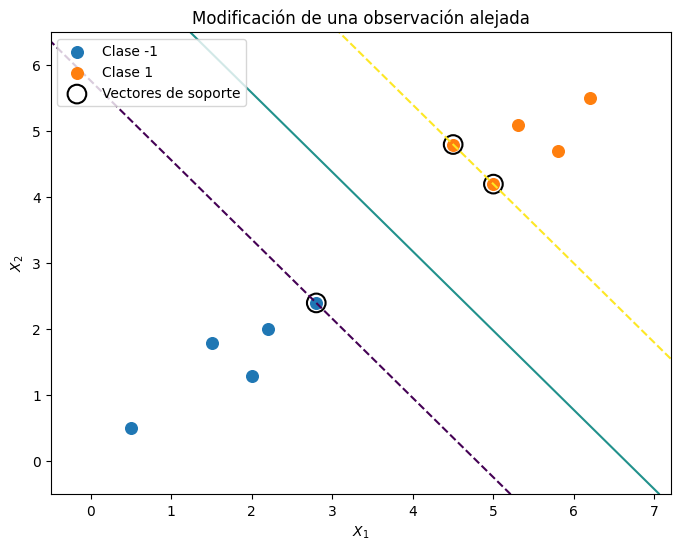

In [34]:
graficar_svm_lineal(modelo_modificado, X_modificado, y, titulo = "Modificación de una observación alejada")

In [35]:
modelo_modificado.coef_

array([[0.54086945, 0.45021752]])

In [37]:
modelo.coef_

array([[0.54086945, 0.45021752]])

In [36]:
modelo_modificado.intercept_

array([-3.59505786])

In [38]:
modelo.intercept_

array([-3.59505786])

## 12.12 Ahora modifiquemos una observación importante.

In [44]:
indice_soporte = modelo.support_[0]

X_soporte_modificado = X.copy()

X_soporte_modificado[indice_soporte] = (X_soporte_modificado[indice_soporte] + np.array([0.5, 0.5]))

X_soporte_modificado

array([[1. , 1. ],
       [1.5, 1.8],
       [2. , 1.3],
       [2.2, 2. ],
       [3.3, 2.9],
       [4.5, 4.8],
       [5. , 4.2],
       [5.3, 5.1],
       [5.8, 4.7],
       [6.2, 5.5]])

In [45]:
modelo_soporte_modificado = SVC(kernel="linear", C = 1e6)

modelo_soporte_modificado.fit(X_soporte_modificado, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


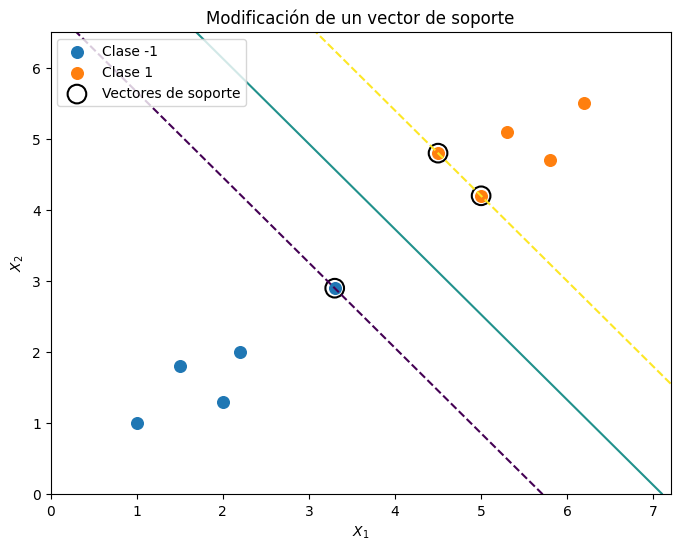

In [46]:
graficar_svm_lineal(modelo_soporte_modificado, X_soporte_modificado, y, titulo = "Modificación de un vector de soporte")

In [47]:
modelo_soporte_modificado.coef_

array([[0.71884161, 0.59862672]])

In [48]:
modelo_soporte_modificado.intercept_

array([-5.10827679])

## 12.13 ¿Un ajuste perfecto garantiza una buena clasificación futura?

In [50]:
rng = np.random.default_rng(123)

X_neg = rng.normal(loc = [2,2], scale = 0.55, size=(50,2))

X_neg

array([[1.45598326, 1.79771734],
       [2.70835889, 2.10668593],
       [2.50612699, 2.31740709],
       [1.64994499, 2.29807372],
       [1.8258725 , 1.82268599],
       [2.05344203, 1.16073828],
       [2.65569136, 1.63090068],
       [2.55014818, 2.07497662],
       [2.84261819, 1.63701682],
       [1.82851283, 2.18577302],
       [0.7858909 , 2.45535679],
       [2.84789672, 2.61974374],
       [2.4151233 , 1.91971216],
       [2.70504622, 2.59071684],
       [2.21594146, 2.00281287],
       [1.80102822, 1.32337229],
       [2.67442611, 0.80537586],
       [1.79641896, 2.09040904],
       [2.47293465, 2.96891368],
       [2.54632808, 1.83966322],
       [2.40047016, 1.30611983],
       [2.78646619, 1.91393857],
       [1.62943247, 1.64851694],
       [1.96625127, 1.78396829],
       [3.25945047, 1.60500037],
       [2.01793426, 2.01542744],
       [2.01554967, 2.03044022],
       [1.73514043, 1.67912587],
       [1.52581172, 1.18150396],
       [2.11896876, 2.54140699],
       [1.

In [51]:
X_pos = rng.normal(loc = [5,5], scale = 0.55, size=(50,2))

In [53]:
X_grande = np.vstack([X_neg, X_pos])

y_grande = np.array([-1]*len(X_neg) + [1]*len(X_pos))

y_grande

array([-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1])

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X_grande, y_grande, test_size = 0.30, random_state=42, stratify= y_grande)

In [56]:
modelo_train = SVC(kernel= "linear", C=1e6)
modelo_train.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [57]:
y_pred_test = modelo_train.predict(X_test)

accuracy_score(y_test, y_pred_test)

1.0

## 12.14 Limitación del margen máximo.

In [58]:
X_no_separable = np.vstack([X, [4.8, 4.6]])
y_no_separable = np.append(y, -1)


In [60]:
modelo_no_separable = SVC(kernel="linear", C = 1e6)
modelo_no_separable.fit(X_no_separable, y_no_separable)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


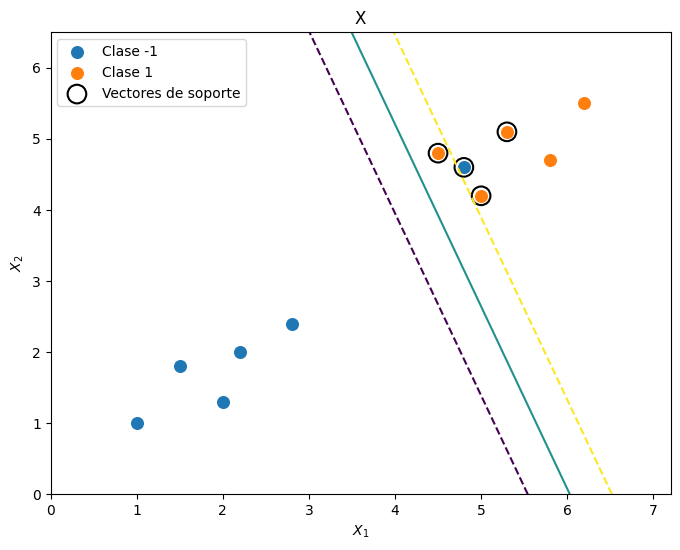

In [61]:
graficar_svm_lineal(modelo_no_separable, X_no_separable, y_no_separable, titulo = "X")

In [62]:

accuracy_score(y_no_separable, modelo_no_separable.predict(X_no_separable))

0.9090909090909091

## Ejercicios

**12.15.1 Ejercicio 1.** Utiliza el conjunto de datos original $X$ y $y$.


In [63]:
modelo1 = SVC(kernel = "linear", C = 1e6)

modelo1.fit(X,y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False



Identifica:

- los índices de los vectores de soporte;

In [65]:
print(modelo1.support_)

[4 5 6]


- las coordenadas de los vectores de soporte;

In [66]:
print(modelo1.support_vectors_)

[[2.8 2.4]
 [4.5 4.8]
 [5.  4.2]]


- el número de vectores de soporte de cada clase.

In [67]:
print(modelo1.n_support_)

[1 2]


Interpreta los resultados utilizando la gráfica.

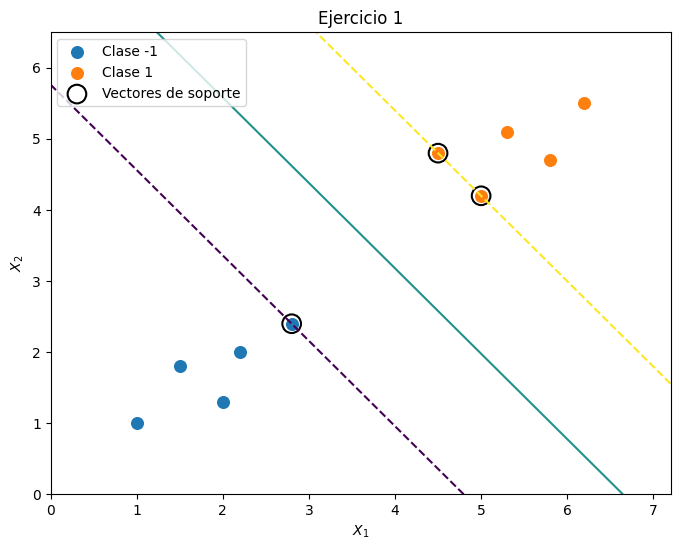

In [68]:
graficar_svm_lineal(modelo1, X, y, titulo = "Ejercicio 1")

EL SVM encontrón una línea que divide excelente las dos clasificaciones. Se necesitó tres vectores de soporte; uno de la clase azul y dos de la clase naranja.

**12.15.2 Ejercicio 2.** Calcula manualmente el valor de la función de decisión para la primera observación:

$$ x_1$$

Utiliza los valores almacenados en beta_0 y beta.

Después compara tu resultado con:

In [70]:
modelo1.coef_

array([[0.54086945, 0.45021752]])

In [71]:
modelo.intercept_

array([-3.59505786])

In [80]:
valor1 = -3.59 + 0.54*X[[0][0]][0] + 0.45*X[[0][0]][1]

In [81]:
print(valor1)

-2.5999999999999996


In [69]:
modelo1.decision_function(X[[0]])

array([-2.60397089])

**12.15.3 Ejercicio 3.** Selecciona una observación que no sea un vector de soporte y modifica ligeramente sus coordenadas.

Vuelve a ajustar el modelo y compara:

In [88]:
X_modificado3 = X.copy()
X_modificado3[8] = [4.0, 4.3]

modelo_modificado3 = SVC(
    kernel="linear",
    C=1e6
)

modelo_modificado3.fit(X_modificado3, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000000.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


- los coeficientes;

In [89]:
modelo_modificado3.coef_

array([[0.47524761, 0.75247538]])

- el término independiente;

In [90]:
modelo_modificado3.intercept_

array([-4.13663467])

- los vectores de soporte;

In [91]:
modelo_modificado3.support_vectors_

array([[2.8, 2.4],
       [4. , 4.3]])

- la frontera de decisión.

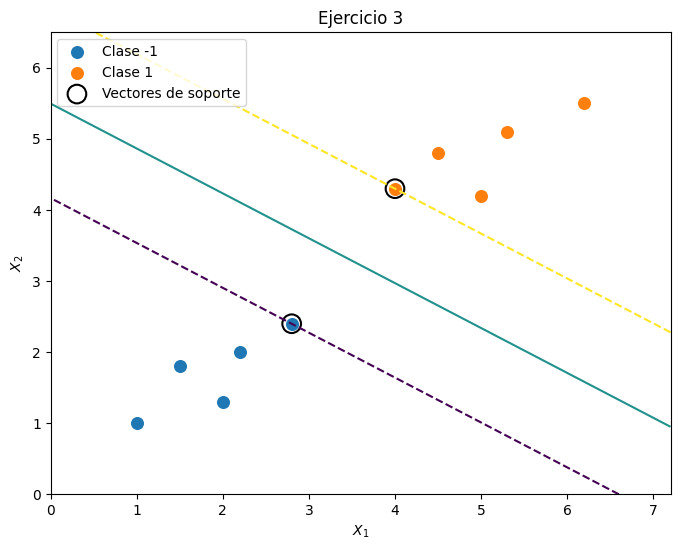

In [92]:
graficar_svm_lineal(modelo_modificado3, X_modificado3, y, titulo="Ejercicio 3")

¿Qué observas?

Los coeficientes y el intercepto cambiaron poco, pero el número de vectores de soporte bajó, además que la recta se inclinó más.